# Tutorial — package `vqc_zx`

Este notebook explica o package **`vqc_zx`** de raiz, como se fosse para uma apresentação.
Cada secção responde a uma pergunta que pode ser feita:

1. O que é o package e para que serve?
2. Como funciona o ZX-calculus e o `full_reduce`?
3. O que é a abordagem sentinel?
4. O que é o `embedding` e que opções existem?
5. O que é o `observable` e qual o impacto de medir só alguns qubits?
6. Como usar o pipeline completo (Phase A + Phase B)?
7. Como interpretar os resultados?
8. O que é a `symbolic_structure`?
9. Por que é que os gates aumentam após extração?
10. CRZ vs CRX — por que se comportam diferente?
11. Testar diferentes embeddings no mesmo circuito
12. Estratégias ZX disponíveis — `full_reduce` vs alternativas
13. Referência rápida — API do package

---
## 0. Setup

In [2]:
import os, sys

# Adicionar o directório raiz (Tese/) ao path — necessário quando o notebook corre de dentro de vqc_zx/
_parent = os.path.dirname(os.path.abspath(os.getcwd()))
if _parent not in sys.path:
    sys.path.insert(0, _parent)

# Adicionar ParamZX ao path
def _find_paramzx():
    cwd = os.getcwd()
    for c in [os.path.join(cwd,'ParamZX'), os.path.join(cwd,'..','ParamZX')]:
        n = os.path.normpath(c)
        if os.path.isdir(os.path.join(n,'pyzx')): return n
    raise FileNotFoundError('ParamZX não encontrado')

pzx = _find_paramzx()
if pzx not in sys.path: sys.path.insert(0, pzx)

import pyzx as zx
import pennylane as qml
from pennylane import numpy as np
import numpy as _np
import matplotlib.pyplot as plt

from vqc_zx import (
    setup_pyzx,
    CircuitRegistry,
    ZXOptimizer,
    STRATEGIES,
    CacheStore,
    VQCEvaluator,
    create_dataset,
    make_embedding,
    make_observable,
    ZXPipeline,
    ZXTracer,
)

print('vqc_zx carregado  ✓')
print('pyzx version:', zx.__version__)

vqc_zx carregado  ✓
pyzx version: 0.7.3


---
## 1. O que é o package e para que serve?


O `vqc_zx` é um framework Python que:
1. **Recebe** um circuito VQC com parâmetros treináveis
2. **Aplica** simplificação ZX-calculus (via PyZX) ao circuito, preservando os parâmetros
3. **Treina e avalia** o circuito original e o circuito simplificado lado a lado

O objetivo é perceber se a representação ZX revela estrutura útil para o treino e se o circuito extraído aprende melhor, igual, ou pior.

**Módulos:**
| Módulo | Responsabilidade |
|--------|------------------|
| `_sentinel` | Gera valores únicos para substituir parâmetros treináveis |
| `optimizer` | Aplica `full_reduce` e extrai o circuito simplificado |
| `tracer` | Regista cada passo do `full_reduce` |
| `registry` | Armazena definições de circuitos com nome |
| `cache` | Persiste resultados ZX em JSON (evita recomputar) |
| `evaluator` | Treina circuitos, define embeddings e observáveis |
| `pipeline` | Orquestra tudo num único objeto |

---
## 2. Como funciona o `full_reduce`?


O `full_reduce` tem duas fases:

**Fase 1 — `interior_clifford_simp`:**
- `spider_simp`: funde spiders adjacentes do mesmo tipo (fases somam)
- `to_gh`: converte todos os X-spiders em Z-spiders com Hadamard edges → estado **graph-like**
- Loop até convergir: `id_simp` (remove identidades grau-2) + `spider_simp` + `pivot_simp` + `lcomp_simp`

**Fase 2 — gadgets:**
- `pivot_gadget_simp`: elimina phase gadgets Clifford
- Alterna com `clifford_simp` até convergir

O passo mais impactante é sempre `id_simp` — elimina os spiders de fio (grau-2, fase 0) que o conversor PennyLane→ZX introduz.

In [3]:
# Ver o full_reduce passo a passo num circuito simples

@qml.qnode(qml.device('default.qubit', wires=4))
def _dummy(params):
    for i in range(4): qml.RX(params[i]*_np.pi, wires=i)
    for i in range(4): qml.RZ(params[i+4]*_np.pi, wires=i)
    qml.CRZ(params[8]*_np.pi, wires=[3,2])
    qml.CRZ(params[9]*_np.pi, wires=[2,1])
    qml.CRZ(params[10]*_np.pi, wires=[1,0])
    return qml.expval(qml.PauliZ(0))

# Usar o ZXTracer para ver os passos
from vqc_zx._sentinel import SentinelMatcher

N_PARAMS = 11
matcher = SentinelMatcher(N_PARAMS)

with qml.queuing.AnnotatedQueue() as q:
    for i in range(4): qml.RX(matcher.sentinels[i]*_np.pi, wires=i)
    for i in range(4): qml.RZ(matcher.sentinels[i+4]*_np.pi, wires=i)
    qml.CRZ(matcher.sentinels[8]*_np.pi, wires=[3,2])
    qml.CRZ(matcher.sentinels[9]*_np.pi, wires=[2,1])
    qml.CRZ(matcher.sentinels[10]*_np.pi, wires=[1,0])
tape = qml.tape.QuantumScript.from_queue(q)
graph = qml.transforms.to_zx(tape)
matcher.assign_symbolic_phases(graph)

tracer = ZXTracer()
steps = tracer.trace(graph)
tracer.print_table(steps)

  #  Regra                       Aplic   Vert  Arest  Simbol   Clif
-------------------------------------------------------------------
  0  inicial                         0     34     36      14     12
  1  spider_simp                     2     27     29      11      8
  2  to_gh [X→Z+H]                   0     27     29      11      8
  3  pivot_simp                      1     25     29      11      6
  4  id_simp                         1     24     28      11      5
  5  to_gh [X→Z+H]                   0     24     28      11      5
  6  pivot_boundary_simp             2     26     33      11      7
  7  final                           0     26     33      11      7

Result: 34 → 26 vertices (23.5% reduction)  |  11 symbolic params surviving


---
## 3. O que é a abordagem sentinel?



**O problema:** o PyZX classifica cada spider como Clifford (múltiplo de π/2) ou não-Clifford. Regras como `pivot` e `lcomp` só se aplicam a spiders Clifford. Se um parâmetro treinável pudesse ser Clifford por acidente, seria simplificado incorretamente.

**A solução — sentinelas:**
- Cada parâmetro `θ_i` é substituído por `s_i = 1/p_i` (em unidades de π), onde `p_i` é o i-ésimo primo começando em 7
- `s_0 = 1/7 ≈ 0.143π`, `s_1 = 1/11 ≈ 0.091π`, ...
- Nenhum sentinela é Clifford (todos afastados de {0, 1/2, 1, 3/2} por pelo menos 0.052)
- O fork **ParamZX** classifica qualquer fase SymPy como não-Clifford → `full_reduce(paramSafe=True)` pula esses spiders
- Após a redução, os spiders sobreviventes têm expressões simbólicas que dizem como o parâmetro original aparece no circuito extraído

In [4]:
from vqc_zx._sentinel import SentinelMatcher

# Ver os valores sentinela
m = SentinelMatcher(8)
print('Sentinelas (unidades de π):')
for i, s in enumerate(m.sentinels):
    print(f'  θ_{i}  →  s_{i} = 1/{[7,11,13,17,19,23,29,31][i]} ≈ {s/(_np.pi):.4f}π')

print()
print('Conjunto Clifford: {0, 0.5π, π, 1.5π}')
print('Distância mínima ao conjunto Clifford:', min(
    min(abs(s/_np.pi - c) for c in [0, 0.5, 1, 1.5])
    for s in m.sentinels
), 'π')

Sentinelas (unidades de π):
  θ_0  →  s_0 = 1/7 ≈ 0.0455π
  θ_1  →  s_1 = 1/11 ≈ 0.0289π
  θ_2  →  s_2 = 1/13 ≈ 0.0245π
  θ_3  →  s_3 = 1/17 ≈ 0.0187π
  θ_4  →  s_4 = 1/19 ≈ 0.0168π
  θ_5  →  s_5 = 1/23 ≈ 0.0138π
  θ_6  →  s_6 = 1/29 ≈ 0.0110π
  θ_7  →  s_7 = 1/31 ≈ 0.0103π

Conjunto Clifford: {0, 0.5π, π, 1.5π}
Distância mínima ao conjunto Clifford: 0.010268060844638409 π


---
## 4. Embeddings disponíveis

> **Pergunta típica:** *"Como é que codificas os dados clássicos no circuito quântico?"*

O **embedding** é a camada que converte o vetor de features clássico `x` em estado quântico, antes de aplicar o ansatz variacional.

| Nome | O que faz | Quando usar |
|------|-----------|-------------|
| `"angle_Y"` (default) | `RY(x_i)` em cada qubit | Features em [0, π]; mais comum em VQC |
| `"angle_X"` | `RX(x_i)` em cada qubit | Alternativa, mesma ideia |
| `"angle_Z"` | `RZ(x_i)` em cada qubit | Features na direção Z; útil se ansatz começa com X-rotações |
| `"amplitude"` | `AmplitudeEmbedding` | Precisa de 2^n_q features; eficiente mas difícil de preparar |
| `"iqp"` | Hadamard + IsingZZ + Hadamard | Kernel quântico estilo IQP; bom para datasets não-lineares |

In [5]:
# Demonstrar os embeddings
x_example = np.array([0.5, 1.2, 0.8, 1.0])
n_q = 4
dev = qml.device('default.qubit', wires=n_q)

for name in ['angle_Y', 'angle_X', 'angle_Z', 'iqp']:
    emb = make_embedding(name)

    @qml.qnode(dev)
    def show_embedding(x, _emb=emb):
        _emb(x, n_q)
        return qml.state()

    print(f'\n--- {name} ---')
    print(qml.draw(show_embedding)(x_example))


--- angle_Y ---
0: ─╭AngleEmbedding(M0)─┤  State
1: ─├AngleEmbedding(M0)─┤  State
2: ─├AngleEmbedding(M0)─┤  State
3: ─╰AngleEmbedding(M0)─┤  State

M0 = 
[0.5 1.2 0.8 1. ]

--- angle_X ---
0: ─╭AngleEmbedding(M0)─┤  State
1: ─├AngleEmbedding(M0)─┤  State
2: ─├AngleEmbedding(M0)─┤  State
3: ─╰AngleEmbedding(M0)─┤  State

M0 = 
[0.5 1.2 0.8 1. ]

--- angle_Z ---
0: ─╭AngleEmbedding(M0)─┤  State
1: ─├AngleEmbedding(M0)─┤  State
2: ─├AngleEmbedding(M0)─┤  State
3: ─╰AngleEmbedding(M0)─┤  State

M0 = 
[0.5 1.2 0.8 1. ]

--- iqp ---
0: ──H─╭IsingZZ(0.60)──H───────────────────────────────┤  State
1: ──H─╰IsingZZ(0.60)─╭IsingZZ(0.96)──H────────────────┤  State
2: ──H────────────────╰IsingZZ(0.96)─╭IsingZZ(0.80)──H─┤  State
3: ──H───────────────────────────────╰IsingZZ(0.80)──H─┤  State


---
## 5. Observáveis e o impacto de medir só alguns qubits

> **Pergunta típica:** *"Por que razão usas a soma de todos os PauliZ? Poderias medir só um qubit?"*

Esta foi uma das lições mais importantes do projeto. No início, media-se apenas `PauliZ(0)` (qubit 0). O resultado: todos os circuitos ficavam com ~55% de acurácia, independentemente da arquitetura.

**Porquê?** Num circuito de 4 qubits com gates de entangling, a informação está distribuída por todos os qubits. Medir só um descarta 3/4 do sinal e o gradiente é insuficiente para treinar.

| Observable | Fórmula | Quando usar |
|------------|---------|-------------|
| `"sum_all"` (default) | `(Z0+Z1+Z2+Z3)/4` | Sempre — sinal máximo de todos os qubits |
| `"sum_subset"` | `(Z0+Z1)/2` | Quando alguns qubits têm papel especial |
| `"single"` | `Z0` | NÃO recomendado para circuitos profundos |
| `"tensor"` | `Z0⊗Z1⊗Z2⊗Z3` | Paridade global; sensível a correlações entre qubits |
| `"parity"` | alias de tensor | — |

In [6]:
# Demonstração: comparar single vs sum_all num circuito real
# (treino rápido, 80 steps, para ver a diferença)

registry = CircuitRegistry()

@registry.register('demo_crz', n_qubits=4, n_params=11)
def demo_crz(params):
    for i in range(4): qml.RX(params[i]*_np.pi, wires=i)
    for i in range(4): qml.RZ(params[i+4]*_np.pi, wires=i)
    qml.CRZ(params[8]*_np.pi, wires=[3,2])
    qml.CRZ(params[9]*_np.pi, wires=[2,1])
    qml.CRZ(params[10]*_np.pi, wires=[1,0])

# Optimizar e cachear
optimizer = ZXOptimizer()
result = optimizer.run(demo_crz, 11)
cache_data = result.to_dict()

X, y = create_dataset(120, 4, seed=42)

results_obs = {}
for obs_name, obs_wires in [('sum_all', None), ('sum_subset', [0,1]), ('single', None), ('tensor', None)]:
    ev = VQCEvaluator(
        registry['demo_crz'], cache_data,
        observable=obs_name, observable_wires=obs_wires,
        lr=0.05,
    )
    r = ev.train(X, y, steps=80, use_optimized=False, seed=0)
    results_obs[obs_name] = r['accuracy_final']
    label = obs_name if not obs_wires else f"{obs_name}({obs_wires})"
    print(f'{label:25} → accuracy {r["accuracy_final"]:.3f}')

sum_all                   → accuracy 0.683
sum_subset([0, 1])        → accuracy 0.733
single                    → accuracy 0.617
tensor                    → accuracy 0.450


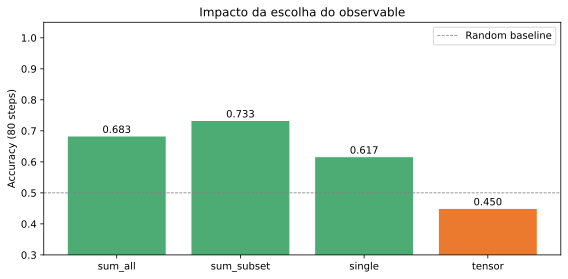

In [7]:
# Gráfico comparativo
fig, ax = plt.subplots(figsize=(8, 4))
names = list(results_obs.keys())
accs  = list(results_obs.values())
colors = ['#2E9E5B' if a > 0.55 else '#E8630A' for a in accs]
bars = ax.bar(names, accs, color=colors, alpha=0.85, edgecolor='white')
ax.axhline(0.5, color='grey', ls='--', lw=0.8, label='Random baseline')
for b, a in zip(bars, accs):
    ax.text(b.get_x()+b.get_width()/2, a+0.01, f'{a:.3f}', ha='center', fontsize=10)
ax.set_ylim(0.3, 1.05)
ax.set_ylabel('Accuracy (80 steps)')
ax.set_title('Impacto da escolha do observable')
ax.legend()
plt.tight_layout()
plt.show()

---
## 6. Pipeline completo — Phase A + Phase B


O `ZXPipeline` orquestra tudo:
- `optimize_all()` — Phase A: aplica ZX e guarda em cache
- `run_experiment()` — Phase B: treina ambos e compara

In [8]:
import tempfile, os

# 1. Registar circuitos
reg = CircuitRegistry()

@reg.register('crz_chain', n_qubits=4, n_params=11)
def crz_chain(params):
    for i in range(4): qml.RX(params[i]*_np.pi, wires=i)
    for i in range(4): qml.RZ(params[i+4]*_np.pi, wires=i)
    qml.CRZ(params[8]*_np.pi, wires=[3,2])
    qml.CRZ(params[9]*_np.pi, wires=[2,1])
    qml.CRZ(params[10]*_np.pi, wires=[1,0])

@reg.register('crx_chain', n_qubits=4, n_params=11)
def crx_chain(params):
    for i in range(4): qml.RX(params[i]*_np.pi, wires=i)
    for i in range(4): qml.RZ(params[i+4]*_np.pi, wires=i)
    qml.CRX(params[8]*_np.pi, wires=[3,2])
    qml.CRX(params[9]*_np.pi, wires=[2,1])
    qml.CRX(params[10]*_np.pi, wires=[1,0])

# 2. Criar pipeline
CACHE_DIR   = os.path.join('zx_cache_tutorial')
RESULTS_DIR = os.path.join('testes', 'results')
pipeline = ZXPipeline(reg, cache_dir=CACHE_DIR, results_dir=RESULTS_DIR)

# 3. Phase A — ZX optimization
print('=== Phase A: ZX Optimization ===')
pipeline.optimize_all()

# 4. Mostrar resumo da Phase A
print()
pipeline.print_summary()

=== Phase A: ZX Optimization ===
[cache/full_reduce] crz_chain: ops 11 → 45  params 11 → 11
[cache/full_reduce] crx_chain: ops 11 → 44  params 11 → 14

Strategy: full_reduce
circuit             ops orig  ops opt  params orig  params opt  symbolic structure
--------------------------------------------------------------------------------
crz_chain                 11       45           11          11  ['a', 'b', 'c', 'd', 'f + j/2', '-i/2', '-j/2', '-k/2', 'h', 'e + k/2', 'g + i/2']
crx_chain                 11       44           11          14  ['a', 'b', 'c', 'd', 'e', 'f', 'g', 'i/2 - 1', '-i/2 - 1', 'j/2 - 1', '-j/2 - 1', 'k/2 - 1', '-k/2 - 1', 'h']


In [9]:
# 5. Phase B — treino e avaliação
print('=== Phase B: Training & Evaluation ===')

X, y = create_dataset(120, 4, seed=42)

# Usar embedding IQP e observable sum_all
run = pipeline.run_experiment(
    X, y,
    steps=150,
    lr=0.05,
    embedding='angle_Y',
    observable='sum_all',
    data_seed=42,
)

print()
pipeline.print_results(run)

=== Phase B: Training & Evaluation ===

strategy=full_reduce  embedding=angle_Y  observable=sum_all
circuit             acc orig   acc opt    delta
--------------------------------------------------
crz_chain              0.975     0.058   -0.917
crx_chain              0.783     0.333   -0.450


---
## 7. Interpretar os resultados



Os resultados dependem do tipo de gate de entangling:

- **CRZ**: os phase gadgets Z fundem-se com Z-rotations → parâmetros podem reduzir → mesma ou melhor accuacy
- **CRX**: após `to_gh`, gera pares `±θ/2` que não se fundem → mais parâmetros → pior accuracy em circuitos profundos
- **CNOT fixos**: sem phase gadgets → a ZX não muda os parâmetros, só o número de gates (overhead)

O número de **gates SEMPRE aumenta** após extração (overhead estrutural do ZX).
O número de **parâmetros** pode reduzir (CRZ) ou aumentar (CRX).

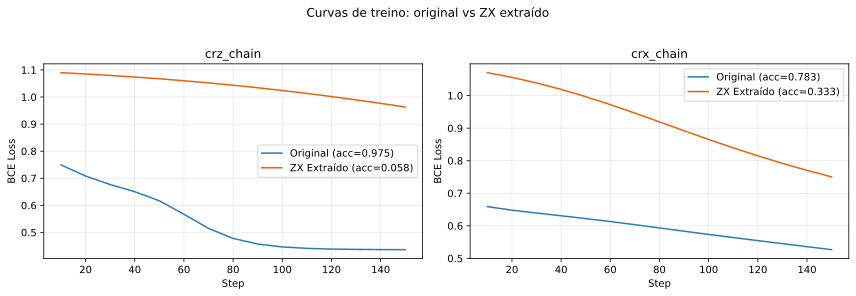

In [10]:
# Visualizar curvas de treino
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
BLUE   = '#2B7BB9'
ORANGE = '#E8630A'

for ax, (name, c) in zip(axes, run['circuits'].items()):
    if c.get('status') != 'ok': continue
    steps_log = list(range(10, 10*(len(c['loss_original'])+1), 10))
    ax.plot(steps_log, c['loss_original'],  color=BLUE,   label=f"Original (acc={c['accuracy_original']:.3f})")
    ax.plot(steps_log, c['loss_optimized'], color=ORANGE, label=f"ZX Extraído (acc={c['accuracy_optimized']:.3f})")
    ax.set_title(name)
    ax.set_xlabel('Step')
    ax.set_ylabel('BCE Loss')
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle('Curvas de treino: original vs ZX extraído', y=1.02)
plt.tight_layout()
plt.show()

---
## 8. O que é a `symbolic_structure`?


A `symbolic_structure` é uma lista de expressões SymPy — uma por gate paramétrico no circuito extraído. Cada expressão diz como o ângulo desse gate se relaciona com os parâmetros originais.

Exemplos reais:
- `'a'` → gate tem o mesmo ângulo que o parâmetro original `a` (θ₀)
- `'e + k/2'` → ângulo é θ₄ + θ₁₀/2 (dois parâmetros originais fundidos)
- `'i/2 - 1'` → metade de θ₈ menos π (vem do CRX após `to_gh`)
- `'-i/2 - 1'` → par do anterior (par CRX: `±θ/2`)

In [11]:
for name in ['crz_chain', 'crx_chain']:
    data = pipeline.cache.get(name)
    print(f'\n=== {name} ===')
    print(f'  Params original: {data["n_params_original"]}  →  extraído: {data["n_params_optimized"]}')
    print(f'  Symbolic structure:')
    for i, expr in enumerate(data['symbolic_structure']):
        print(f'    gate {i:2d}: {expr}')


=== crz_chain ===
  Params original: 11  →  extraído: 11
  Symbolic structure:
    gate  0: a
    gate  1: b
    gate  2: c
    gate  3: d
    gate  4: f + j/2
    gate  5: -i/2
    gate  6: -j/2
    gate  7: -k/2
    gate  8: h
    gate  9: e + k/2
    gate 10: g + i/2

=== crx_chain ===
  Params original: 11  →  extraído: 14
  Symbolic structure:
    gate  0: a
    gate  1: b
    gate  2: c
    gate  3: d
    gate  4: e
    gate  5: f
    gate  6: g
    gate  7: i/2 - 1
    gate  8: -i/2 - 1
    gate  9: j/2 - 1
    gate 10: -j/2 - 1
    gate 11: k/2 - 1
    gate 12: -k/2 - 1
    gate 13: h


---
## 9. Por que é que os gates aumentam após extração?


Esta é a pergunta mais importante! A resposta é:

O grafo ZX simplificado tem **menos vértices (spiders)** — mas o grafo e o circuito são representações diferentes.

Num grafo **graph-like** (após `to_gh`), toda a conectividade interior é expressa por **Hadamard edges**. Quando o algoritmo de extração converte o grafo de volta a um circuito, precisa de implementar cada Hadamard edge com **gates H + CZ explícitos**. É este processo que introduz os gates extra.

Não é um bug — é uma consequência fundamental da representação. O grafo ZX é mais compacto que qualquer circuito possível para o mesmo mapa unitário.

In [12]:
print(f"{'Circuito':<14} {'Gates orig':>10} {'Gates ZX':>9} {'Fator':>6}")
print('-' * 44)
for name in ['crz_chain', 'crx_chain']:
    d = pipeline.cache.get(name)
    factor = d['n_ops_optimized'] / d['n_ops_original']
    print(f"{name:<14} {d['n_ops_original']:10} {d['n_ops_optimized']:9} {factor:6.1f}x")

Circuito       Gates orig  Gates ZX  Fator
--------------------------------------------
crz_chain              11        45    4.1x
crx_chain              11        44    4.0x


---
## 10. CRZ vs CRX — porque se comportam de fomas diferentes?


**CRZ(θ)** → cria phase gadgets no eixo Z:
- No grafo ZX, um CRZ aparece como dois spiders Z com fases `+θ/2` e `-θ/2`
- Estes spiders são **adjacentes a outros Z-spiders** (das rotações RZ)
- `spider_simp` funde-os → o ângulo do gate extraído é `φ + θ/2` (combinação dos dois)
- **Parâmetros: mantêm-se ou reduzem**

**CRX(θ)** → controlo no eixo X:
- Após `to_gh` (que converte todos os X-spiders em Z+H), cada CRX gera dois spiders com fases `+θ/2` e `-θ/2` em partes diferentes do grafo
- Estes spiders **não têm Z-spiders adjacentes** com quem fundir
- Sobrevivem independentes no circuito extraído
- **Parâmetros: aumentam** (3 CRX → 6 meios-ângulos)

A diferença é estrutural: o CRZ "fala a mesma língua" que o grafo ZX graph-like (eixo Z). O CRX não.

In [13]:
# Demonstração visual: ver as expressões simbólicas
import sympy as sym

for name, label in [('crz_chain', 'CRZ (3 gates)'), ('crx_chain', 'CRX (3 gates)')]:
    d = pipeline.cache.get(name)
    exprs = [sym.sympify(e) for e in d['symbolic_structure']]
    frees = sorted(set(str(s) for e in exprs for s in e.free_symbols))
    print(f'\n{label}')
    print(f'  Símbolos únicos (parâmetros): {frees}')
    print(f'  → {len(frees)} parâmetros efetivos (original: {d["n_params_original"]})')
    print(f'  Expressões:')
    for e in exprs:
        print(f'    {e}')


CRZ (3 gates)
  Símbolos únicos (parâmetros): ['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k']
  → 11 parâmetros efetivos (original: 11)
  Expressões:
    a
    b
    c
    d
    f + j/2
    -i/2
    -j/2
    -k/2
    h
    e + k/2
    g + i/2

CRX (3 gates)
  Símbolos únicos (parâmetros): ['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k']
  → 11 parâmetros efetivos (original: 11)
  Expressões:
    a
    b
    c
    d
    e
    f
    g
    i/2 - 1
    -i/2 - 1
    j/2 - 1
    -j/2 - 1
    k/2 - 1
    -k/2 - 1
    h


---
## 11. Testar diferentes embeddings no mesmo circuito

> **Pergunta típica:** *"Já que implementaste vários embeddings, qual é o melhor?"*

A resposta depende do dataset e do ansatz. Aqui comparamos `angle_Y`, `angle_Z` e `iqp` no mesmo circuito.

In [14]:
X, y = create_dataset(120, 4, seed=42)
crz_data = pipeline.cache.get('crz_chain')

emb_results = {}
for emb_name in ['angle_Y', 'angle_X', 'angle_Z', 'iqp']:
    try:
        ev = VQCEvaluator(
            reg['crz_chain'], crz_data,
            embedding=emb_name,
            observable='sum_all',
            lr=0.05,
        )
        r = ev.train(X, y, steps=150, use_optimized=False, seed=0)
        emb_results[emb_name] = r['accuracy_final']
        print(f'{emb_name:12}: acc={r["accuracy_final"]:.3f}')
    except Exception as e:
        print(f'{emb_name:12}: ERRO — {e}')

angle_Y     : acc=0.917
angle_X     : acc=0.950
angle_Z     : acc=0.508
iqp         : acc=0.667


In [15]:
---
## 13. Referência rápida — API do package

```python
from vqc_zx import (
    setup_pyzx,          # Adiciona ParamZX ao sys.path
    CircuitRegistry,     # Armazena circuitos com nome
    ZXOptimizer,         # Aplica estratégia ZX e extrai
    STRATEGIES,          # Dict com estratégias disponíveis
    CacheStore,          # Persiste resultados ZX em JSON
    VQCEvaluator,        # Treina e avalia circuitos
    create_dataset,      # Gera dataset de classificação
    make_embedding,      # Cria função de embedding por nome
    make_observable,     # Cria observable por nome
    ZXPipeline,          # Orquestra tudo
    ZXTracer,            # Trace passo a passo do full_reduce
)

# Embeddings: 'angle_Y', 'angle_X', 'angle_Z', 'amplitude', 'iqp'
# Observáveis: 'sum_all', 'sum_subset', 'single', 'tensor'/'parity'
# Estratégias: 'full_reduce', 'clifford_simp', 'interior_clifford', 'pivot_gadget'

# Fluxo típico:
reg = CircuitRegistry()

@reg.register('meu_circuito', n_qubits=4, n_params=11)
def meu_circuito(params): ...

pipeline = ZXPipeline(
    reg,
    cache_dir='./zx_cache',      # ficheiros: meu_circuito__full_reduce.json
    results_dir='./results',     # ficheiros: angle_Y__sum_all__full_reduce.json
    strategy='full_reduce',      # 'full_reduce' | 'clifford_simp' | 'interior_clifford' | 'pivot_gadget'
)
pipeline.optimize_all()          # Phase A — corre uma vez, cacheia por (circuito, estratégia)

X, y = create_dataset(120, 4)
run = pipeline.run_experiment(   # Phase B — treino
    X, y, steps=200,
    embedding='angle_Y',         # 'angle_Y' | 'angle_X' | 'angle_Z' | 'amplitude' | 'iqp'
    observable='sum_all',        # 'sum_all' | 'sum_subset' | 'single' | 'tensor'
)
pipeline.print_results(run)
pipeline.save_results(run)       # auto-nome: embedding__observable__strategy.json
```

SyntaxError: invalid syntax (815954878.py, line 1)

In [ ]:
# Usar o pipeline com uma estratégia específica
# A cache e os ficheiros de resultados ficam separados por estratégia automaticamente

import tempfile

for strat in ['full_reduce', 'interior_clifford']:
    p = ZXPipeline(
        reg_strat,
        cache_dir=f'zx_cache_tutorial/{strat}',
        results_dir='testes/results',
        strategy=strat,
    )
    p.optimize_all()

print()
print("Cache files criados:")
import os, glob
for f in sorted(glob.glob('zx_cache_tutorial/**/*.json', recursive=True)):
    print(f'  {f}')

---
## 12. Estratégias ZX disponíveis — `full_reduce` vs alternativas

> **Pergunta típica:** *"O `full_reduce` é a única opção? Poderias usar uma simplificação mais conservadora?"*

O package suporta quatro estratégias, todas **param-safe** (não corrompem expressões SymPy):

| Estratégia | Regras aplicadas | Uso |
|------------|------------------|-----|
| `"full_reduce"` (default) | Suite Clifford completa + `pivot_gadget_simp` | Máxima simplificação |
| `"clifford_simp"` | Interior Clifford + pivot boundary | Conservador; sem phase gadgets |
| `"interior_clifford"` | `spider_simp`, `to_gh`, loop `id/pivot/lcomp` | O mais rápido; baseline |
| `"pivot_gadget"` | Interior Clifford + `pivot_gadget_simp` | Intermédio |

**O que NÃO é incluído (e porquê):**
- `gadget_simp`: funde phase gadgets com fases simbólicas → pode corromper expressões SymPy
- `supplementarity_simp`: compara fases com o conjunto Clifford → falha com símbolos SymPy

A cache é separada por estratégia: `circuito_3__full_reduce.json` vs `circuito_3__clifford_simp.json`.
Os ficheiros de resultados também: `angle_Y__sum_all__full_reduce.json`.

---
## 12. Referência rápida — API do package

```python
from vqc_zx import (
    setup_pyzx,          # Adiciona ParamZX ao sys.path
    CircuitRegistry,     # Armazena circuitos com nome
    ZXOptimizer,         # Aplica full_reduce e extrai
    CacheStore,          # Persiste resultados ZX em JSON
    VQCEvaluator,        # Treina e avalia circuitos
    create_dataset,      # Gera dataset de classificação
    make_embedding,      # Cria função de embedding por nome
    make_observable,     # Cria observable por nome
    ZXPipeline,          # Orquestra tudo
    ZXTracer,            # Trace passo a passo do full_reduce
)

# Embeddings: 'angle_Y', 'angle_X', 'angle_Z', 'amplitude', 'iqp'
# Observáveis: 'sum_all', 'sum_subset', 'single', 'tensor'/'parity'

# Fluxo típico:
reg = CircuitRegistry()

@reg.register('meu_circuito', n_qubits=4, n_params=11)
def meu_circuito(params): ...

pipeline = ZXPipeline(reg, cache_dir='./cache', results_dir='./results')
pipeline.optimize_all()                # Phase A — corre uma vez, cacheia

X, y = create_dataset(120, 4)
run = pipeline.run_experiment(         # Phase B — treino
    X, y, steps=200,
    embedding='angle_Y',
    observable='sum_all',
)
pipeline.print_results(run)
pipeline.save_results(run)
```